In [ ]:
#the previous folder was not well organised and was getting a bit convoluted so I'm writing some new functions here. A lot of the code will be stuff that was repeated from the previous folder but that doesn't really matter 

In [1]:
import torch as t 
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np 
import scipy
import os 
import pymannkendall as mk
from scipy import stats as scStats 
from scipy import signal

In [4]:
class DataLoader:
    def __init__(self, directory, years, months):
        self.directory = directory
        self.years = years
        self.months = months 

    def get_file_location(self, year, month):
        poss_formats = [f"f-{year}-{month}.csv", f"fnew-{year}-{month}.csv", f"fNew {year} {month}.csv", f"f {year} {month}.csv"]
        for x in poss_formats:
            path = os.path.join(self.directory, x)
            if os.path.exists(path):
                print(f"found {year}/{month}")
                return path 
        raise FileNotFoundError(F"couldn't find file {year}/{month} with any of the specified formats")

    def run_on_data(self, func):
        output = []
        for year in self.years:
            for month in self.months:
                loc = self.get_file_location(year, month)
                data = pd.read_csv(loc)
                output.append(func(data))
                print(f"{year}/{month} evaluated")
        return output 

    def run_on_data_annual_statistic(self, func, statistic):
        #this calculates a statistic on the month data after each 12 months to save memory 
        output = []
        for year in self.years:
            year_output = []
            for month in self.months:
                loc = self.get_file_location(year, month)
                data = pd.read_csv(loc)
                year_output.extend(func(data))
                print(f"{year}/{month} evaluated")
            output.append(statistic(year_output))
        return output

In [ ]:
#to run the mean_absolute_First_Freq_differnce, we need to modify the dataloader to do the calculations after each year

In [59]:
class Statistics:
    def mean_absolute_first_freq_difference(self, month_data):
        data = month_data["f"].to_numpy()
        differences = data[1:] - data[:-1]
        absolute_differences = np.abs(differences)
        return absolute_differences

    def integral_freq_deviation(self, month_data):
        data = month_data["f"].to_numpy()
        integral = np.abs(data-50).sum()
        return integral 

    def frequency_variance(self, month_data):
        data = month_data["f"].to_numpy() 
        return np.var(data)
    def zero_crossing_rate(self, month_data):
        data = month_data["f"].to_numpy()
        normalised_data = data - 50
        adjacents = normalised_data[1:] * normalised_data[:-1]
        crossings = adjacents[adjacents < 0]
        return len(crossings)
    
    def recovery_rates(self, month_data):
        threshold = 49.8
        data = t.tensor(month_data["f"].to_numpy())
        deviation_locs = t.where(data < threshold)[0]
        if len(deviation_locs) == 0:
            return []
        breaks = t.where(deviation_locs[1:] - deviation_locs[:-1] > 1)[0]+1 
        starts = t.cat((deviation_locs[:1], deviation_locs[breaks]))
        ends = t.cat((deviation_locs[breaks-1], deviation_locs[-1:]))

        results = []
        for start, end in zip(starts, ends):
            segment = data[start:end+1]
            min_idx = t.argmin(segment) + start 
            min_val = data[min_idx]
            recovery_candidates = t.where(
                data[end+1:] >= threshold
            )[0]
            if len(recovery_candidates) == 0:
                continue 
            recovery_idx = end + 1 + recovery_candidates[0]
            recovery_val = data[recovery_idx]
            rate = (recovery_val - min_val) / (recovery_idx - min_idx)

            results.append({
                "minimum": min_val.item(),
                "minimum_time": min_idx.item(),
                "recovery_value": recovery_val.item(),
                "recovery_time": recovery_idx.item(),
                "recovery_rate": rate.item()
            })
        return results

    def skewness(self, month_data):
        data = month_data["f"].to_numpy() 
        return scStats.skew(data) 
    def kurtosis(self, month_data):
        data = month_data["f"].to_numpy()
        return scStats.kurtosis(data)

        
    def spectral_exponent(self, month_data):
        data = month_data["f"].to_numpy() 
        data = data - data.mean() 
        n = len(data)
        fs = 1.0
        window = np.hanning(n)
        X = np.fft.rfft(x * window)
        freqs = np.fft.rfftfreq(n, d=1/fs)
        psd = (np.abs(X) **2) / (fs * np.sum(window**2))
        psd[1:-1] *= 2
        f_min = 0.01
        f_max = 0.2
        band = (freqs >= f_min) & (freqs  <= f_max) & (psd > 0)
        slope, _ = np.polyfit(np.log10(freqs[band]), np.log10(psd[band]), 1)
        return -slope 

        


In [21]:
class PostDataStats:
    #this class is for stuff applied to data after it's undergone basic processing from the csv 
    def getPercentiles(data):
        data = np.array(data)
        return np.percentile(data, [5, 50])

    def man_kendall(data):
        return mk.original_test(data)

    def linear_regress(data):
        return scStats.linregress([x for x in range(len(data))], data)

    def spearman(data1, data2):
        rho, p = stats.spearmanr(data1, data2)
        return rho, p

    def get_regression_line(data):
        res = scStats.linregress([x for x in range(len(data))], data)
        x_domain = np.array([x for x in range(len(data))])
        y_domain = res.slope * x_domain + res.intercept
        return y_domain
    

In [10]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = Statistics()
result = dataloader.run_on_data_annual_statistic(stats.mean_absolute_first_freq_difference, PostDataStats.getPercentiles)
print(result)   

found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

In [14]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = Statistics()
deviation_result = dataloader.run_on_data(stats.integral_freq_deviation)

found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

In [12]:
from datetime import datetime
def construct_date_axis(length, start_year): # we are assuming the original data is compiled monthly from 1st jan that year
    dates = []
    for year in range(length // 12):
        for month in range(12):
            dates.append(datetime(year + start_year, month+1, 1))
    return dates




Mann_Kendall_Test(trend='increasing', h=np.True_, p=np.float64(0.0), z=np.float64(10.526904306856517), Tau=np.float64(0.650140056022409), s=np.float64(4642.0), var_s=194366.66666666666, slope=np.float64(417.94954166666514), intercept=np.float64(119478.20777083359))


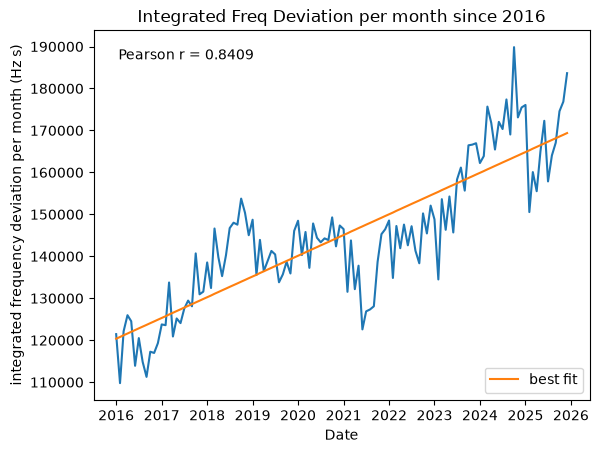

In [ ]:
plt.plot(construct_date_axis(len(deviation_result), 2016), deviation_result)
plt.plot(construct_date_axis(len(deviation_result), 2016), PostDataStats.get_regression_line(deviation_result), label="best fit")
plt.xlabel("Date")
plt.ylabel("integrated frequency deviation per month (Hz s)")
regression = PostDataStats.linear_regress(deviation_result)
plt.text(0.05, 0.95,
         f"Pearson r = {regression.rvalue:.4f}",
         transform=plt.gca().transAxes,
         verticalalignment='top',
         fontsize=10)
plt.legend()
plt.title("Integrated Freq Deviation per month since 2016")


In [62]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = Statistics()
deviation_result = dataloader.run_on_data(stats.frequency_variance)


found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

In [34]:
print(deviation_result)

[np.float64(0.0031212508472400415), np.float64(0.0029303966314969026), np.float64(0.00313987695260978), np.float64(0.0035283861345956303), np.float64(0.0032720776627303562), np.float64(0.0029553701927583402), np.float64(0.0030813498998073776), np.float64(0.0027858632463549473), np.float64(0.002833582387826357), np.float64(0.0030198577669621404), np.float64(0.0031985442816841346), np.float64(0.0030589215448962722), np.float64(0.0032800474108030503), np.float64(0.003963003933106521), np.float64(0.003787341690573071), np.float64(0.003318159915081101), np.float64(0.0032768926355252336), np.float64(0.003438261992755906), np.float64(0.003416000065135178), np.float64(0.0035551878678710736), np.float64(0.0036714117909526453), np.float64(0.004230188188426913), np.float64(0.0038725880206356093), np.float64(0.0036638745679224666), np.float64(0.003976150721711959), np.float64(0.004440628246495167), np.float64(0.004441325235714746), np.float64(0.004286259919116078), np.float64(0.0037375399314769193

In [64]:
variance_mk = mk.seasonal_test(deviation_result, period=12)
print(variance_mk)

Seasonal_Mann_Kendall_Test(trend='increasing', h=np.True_, p=np.float64(0.0), z=np.float64(9.734098143467975), Tau=np.float64(0.7), s=np.float64(378.0), var_s=1500.0, slope=np.float64(0.00023307379552856954), intercept=np.float64(0.003213697720339731))


Text(0.5, 1.0, 'Frequency variance per month since 2016')

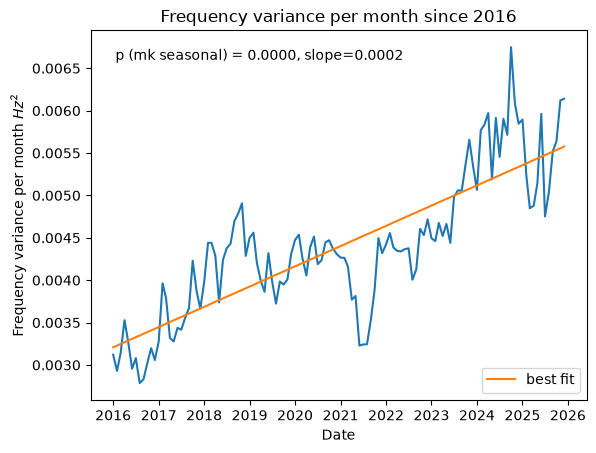

In [66]:
plt.plot(construct_date_axis(len(deviation_result), 2016), deviation_result)
plt.plot(construct_date_axis(len(deviation_result), 2016), PostDataStats.get_regression_line(deviation_result), label="best fit")
plt.xlabel("Date")
plt.ylabel("Frequency variance per month $Hz^2$")
regression = PostDataStats.linear_regress(deviation_result)
plt.text(0.05, 0.95,
         f"p (mk seasonal) = {variance_mk.p:.4f}, slope={variance_mk.slope:.4f}",
         transform=plt.gca().transAxes,
         verticalalignment='top',
         fontsize=10)
plt.legend()
plt.title("Frequency variance per month since 2016")


In [41]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = Statistics()
deviation_result = dataloader.run_on_data(stats.mean_absolute_first_freq_difference)

found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

In [44]:
print(deviation_result)

[array([0.003, 0.007, 0.009, ..., 0.002, 0.003, 0.002], shape=(2678399,)), array([0.004, 0.006, 0.011, ..., 0.002, 0.001, 0.001], shape=(2505599,)), array([0.006, 0.006, 0.013, ..., 0.001, 0.002, 0.003], shape=(2678399,)), array([0.002, 0.007, 0.009, ..., 0.003, 0.003, 0.002], shape=(2591999,)), array([0.006, 0.008, 0.015, ..., 0.   , 0.003, 0.003], shape=(2678399,)), array([0.001, 0.002, 0.012, ..., 0.002, 0.006, 0.001], shape=(2591999,)), array([0.004, 0.003, 0.009, ..., 0.001, 0.001, 0.   ], shape=(2678399,)), array([0.003, 0.003, 0.011, ..., 0.003, 0.001, 0.002], shape=(2678399,)), array([0.001, 0.006, 0.001, ..., 0.001, 0.002, 0.   ], shape=(2591999,)), array([0.003, 0.003, 0.006, ..., 0.001, 0.002, 0.001], shape=(2678399,)), array([0.004, 0.006, 0.006, ..., 0.001, 0.002, 0.001], shape=(2591999,)), array([0.005, 0.006, 0.007, ..., 0.001, 0.001, 0.002], shape=(2678399,)), array([0.004, 0.006, 0.007, ..., 0.   , 0.001, 0.   ], shape=(2678399,)), array([0.003, 0.002, 0.003, ..., 0.00

In [47]:
percentile_5_frequency_diffs = []
median_frequency_diffs = []

for x in deviation_result:
    p5 = np.percentile(x, 10)
    p50 = np.percentile(x, 50)
    percentile_5_frequency_diffs.append(p5)
    median_frequency_diffs.append(p50)


In [ ]:
print(p5)

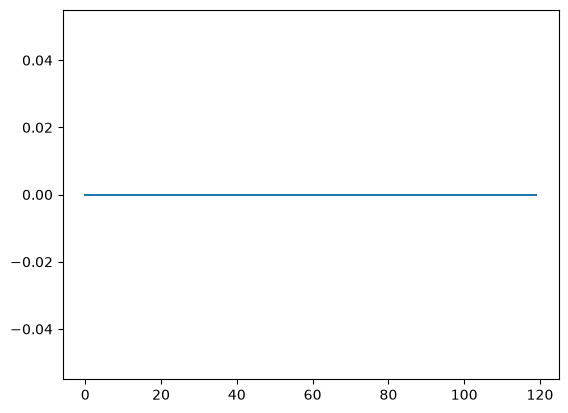

In [48]:
plt.plot([x for x in range(120)], percentile_5_frequency_diffs)

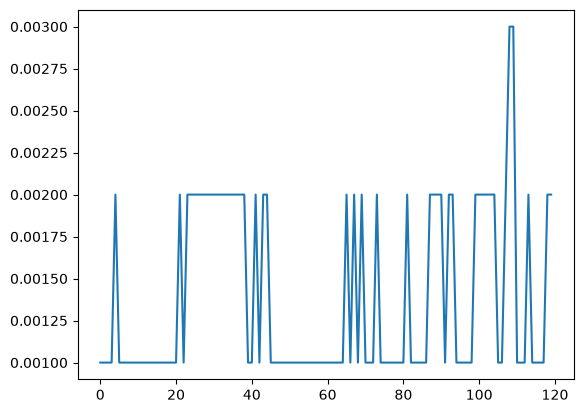

In [49]:
plt.plot([x for x in range(120)], median_frequency_diffs)

In [52]:
annual_mean_freq_step = [np.float64(0.0016231946706205733), np.float64(0.0017695884444541207), np.float64(0.0017936806187321356), np.float64(0.0017635758128519221), np.float64(0.0016800325369395717), np.float64(0.0017188501611802673), np.float64(0.0018092692853451118), np.float64(0.0018581639896561488), np.float64(0.0019375823046672343), np.float64(0.002228207727514374)]

statistic_for_steps = PostDataStats.man_kendall(annual_mean_freq_step)
print(statistic_for_steps)

Mann_Kendall_Test(trend='increasing', h=np.True_, p=np.float64(0.01226606138621289), z=np.float64(2.5043961347997645), Tau=np.float64(0.6444444444444445), s=np.float64(29.0), var_s=125.0, slope=np.float64(3.881762424069561e-05), intercept=np.float64(0.001606955222509998))


In [67]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = Statistics()
crossing_rates= dataloader.run_on_data(stats.zero_crossing_rate)

found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

In [69]:
crossing_mk = mk.seasonal_test(crossing_rates, period=12)
print(crossing_mk)

Seasonal_Mann_Kendall_Test(trend='decreasing', h=np.True_, p=np.float64(3.58745099398039e-05), z=np.float64(-4.132559985613009), Tau=np.float64(-0.29814814814814816), s=np.float64(-161.0), var_s=np.float64(1499.0), slope=np.float64(-356.7), intercept=np.float64(13015.1375))


0.5234219093726717


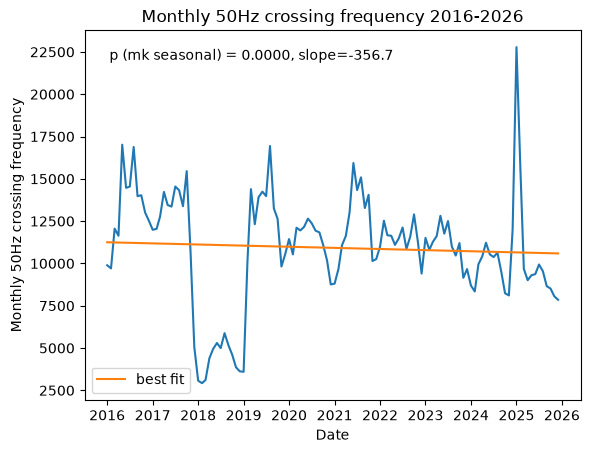

In [70]:
plt.plot(construct_date_axis(len(crossing_rates), 2016), crossing_rates)
plt.xlabel("Date")
plt.ylabel("Monthly 50Hz crossing frequency")
plt.title("Monthly 50Hz crossing frequency 2016-2026")
plt.plot(construct_date_axis(len(crossing_rates), 2016), PostDataStats.get_regression_line(crossing_rates), label="best fit")

regression = PostDataStats.linear_regress(crossing_rates)
plt.text(0.05, 0.95,
         f"p (mk seasonal) = {crossing_mk.p:.4f}, slope={crossing_mk.slope}",
         transform=plt.gca().transAxes,
         verticalalignment='top',
         fontsize=10)
plt.legend()

print(regression.pvalue)
#pvalue is 0.5234219093726717 

In [71]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = Statistics()
deviation_result = dataloader.run_on_data(stats.recovery_rates)

found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

In [73]:
recovery_results = deviation_result
minor_deviations = []
for x in recovery_results:
    minor_deviations.append(len(x))


In [74]:
mk_monthly_minor = mk.seasonal_test(minor_deviations)
print(mk_monthly_minor)

Seasonal_Mann_Kendall_Test(trend='increasing', h=np.True_, p=np.float64(5.711462480739726e-08), z=np.float64(5.427607008219308), Tau=np.float64(0.3907407407407407), s=np.float64(211.0), var_s=np.float64(1497.0), slope=np.float64(8.25), intercept=np.float64(18.59375))


2.7378017275505285e-06


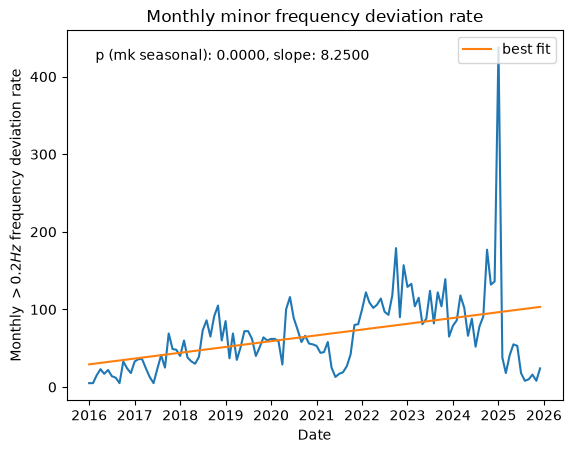

In [77]:


plt.plot(construct_date_axis(len(minor_deviations), 2016), minor_deviations)
plt.xlabel("Date")
plt.ylabel("Monthly $>0.2Hz$ frequency deviation rate")
plt.title("Monthly minor frequency deviation rate")

plt.plot(construct_date_axis(len(minor_deviations), 2016), PostDataStats.get_regression_line(minor_deviations), label="best fit")
regression = PostDataStats.linear_regress(minor_deviations)
plt.text(0.05, 0.95,
         f" p (mk seasonal): {mk_monthly_minor.p:.4f}, slope: {mk_monthly_minor.slope:.4f}",
         transform=plt.gca().transAxes,
         verticalalignment='top',
         fontsize=10)
plt.legend(loc="upper right")
print(regression.pvalue)


In [78]:
minima = []
rates = []
for x in recovery_results:
    minima_for_month = []
    rates_for_month = []
    for y in x:
        minima_for_month.append(y["minimum"])
        rates_for_month.append(y["recovery_rate"])
    minima.append(minima_for_month)
    rates.append(rates_for_month)
print(minima)
print(rates)



[[49.771, 49.799, 49.631, 49.668, 49.757], [49.789, 49.794, 49.791, 49.797, 49.791], [49.794, 49.797, 49.776, 49.792, 49.792, 49.794, 49.799, 49.794, 49.781, 49.738, 49.799, 49.79, 49.792, 49.795, 49.793], [49.798, 49.782, 49.759, 49.774, 49.797, 49.792, 49.792, 49.783, 49.779, 49.779, 49.793, 49.793, 49.793, 49.798, 49.783, 49.792, 49.798, 49.797, 49.77, 49.781, 49.797, 49.747, 49.775], [49.782, 49.758, 49.793, 49.702, 49.795, 49.768, 49.774, 49.798, 49.798, 49.799, 49.787, 49.792, 49.777, 49.798, 49.797, 49.789, 49.796], [49.793, 49.767, 49.776, 49.799, 49.792, 49.791, 49.79, 49.588, 49.776, 49.793, 49.778, 49.714, 49.798, 49.792, 49.792, 49.714, 49.793, 49.604, 49.789, 49.783, 49.793, 49.787], [49.794, 49.788, 49.799, 49.782, 49.792, 49.79, 49.79, 49.794, 49.747, 49.737, 49.796, 49.755, 49.794, 49.707], [49.799, 49.799, 49.585, 49.791, 49.791, 49.765, 49.789, 49.792, 49.755, 49.799, 49.795, 49.787], [49.69, 49.791, 49.65, 49.795, 49.791], [49.773, 49.781, 49.778, 49.795, 49.792, 49.

In [80]:
largest_drop = []
slowest_recovery = []
for x in range(len(minima)):
    largest_drop.append(min(minima[x]))
    slowest_recovery.append(min(rates[x]))

In [81]:
largest_drop_mk = mk.seasonal_test(largest_drop)
slowest_recovery_mk = mk.seasonal_test(slowest_recovery)
print(largest_drop_mk)
print(slowest_recovery_mk)

Seasonal_Mann_Kendall_Test(trend='no trend', h=np.False_, p=np.float64(0.4857170594010729), z=np.float64(0.697137002317335), Tau=np.float64(0.05185185185185185), s=np.float64(28.0), var_s=1500.0, slope=np.float64(0.0012000000000000454), intercept=np.float64(49.691050000000004))
Seasonal_Mann_Kendall_Test(trend='decreasing', h=np.True_, p=np.float64(3.237603518613241e-10), z=np.float64(-6.28695150928413), Tau=np.float64(-0.45), s=np.float64(-243.0), var_s=np.float64(1481.6666666666665), slope=np.float64(-3.3788224712633533e-05), intercept=np.float64(0.0006107730767851679))


0.38968987507863606


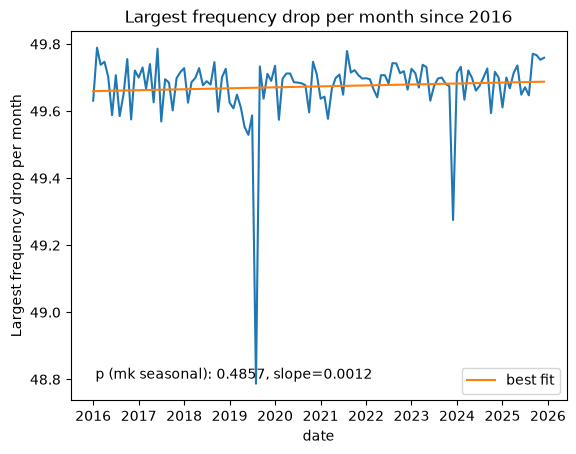

In [82]:


plt.plot(construct_date_axis(len(largest_drop), 2016), largest_drop)
plt.xlabel("date")
plt.ylabel("Largest frequency drop per month")
plt.title("Largest frequency drop per month since 2016")
plt.plot(construct_date_axis(len(largest_drop), 2016), PostDataStats.get_regression_line(largest_drop), label="best fit")
regression = PostDataStats.linear_regress(largest_drop)
plt.text(0.05, 0.05,
         f"p (mk seasonal): {largest_drop_mk.p:.4f}, slope={largest_drop_mk.slope:.4f}",
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         fontsize=10)
plt.legend(loc="lower right")
print(regression.pvalue)

2.3800722994145243e-11


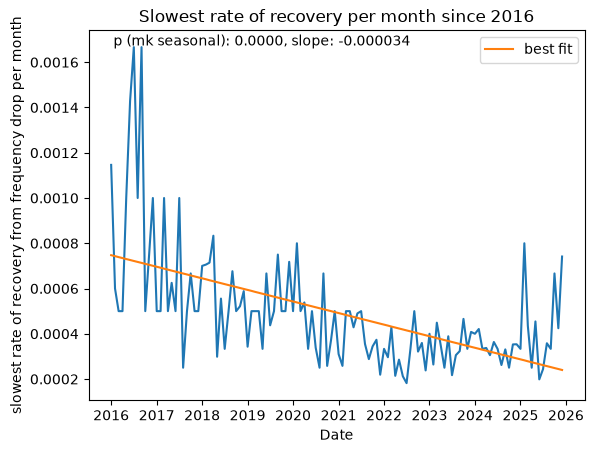

In [84]:
plt.plot(construct_date_axis(len(slowest_recovery), 2016), slowest_recovery)
plt.xlabel("Date")
plt.ylabel("slowest rate of recovery from frequency drop per month")
plt.plot(construct_date_axis(len(slowest_recovery), 2016), PostDataStats.get_regression_line(slowest_recovery), label="best fit")
regression = PostDataStats.linear_regress(slowest_recovery)
plt.text(0.05, 0.95,
         f"p (mk seasonal): {slowest_recovery_mk.p:.4f}, slope: {slowest_recovery_mk.slope:.6f}",
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         fontsize=10)
plt.legend(loc="upper right")
plt.title("Slowest rate of recovery per month since 2016")
print(regression.pvalue)

In [91]:
print(recovery_results)

[[{'minimum': 49.771, 'minimum_time': 255714, 'recovery_value': 49.801, 'recovery_time': 255725, 'recovery_rate': 0.0027272727272728307}, {'minimum': 49.799, 'minimum_time': 558210, 'recovery_value': 49.803, 'recovery_time': 558212, 'recovery_rate': 0.0019999999999988916}, {'minimum': 49.631, 'minimum_time': 879404, 'recovery_value': 49.806, 'recovery_time': 879413, 'recovery_rate': 0.01944444444444413}, {'minimum': 49.668, 'minimum_time': 1066818, 'recovery_value': 49.941, 'recovery_time': 1066819, 'recovery_rate': 0.27300000000000324}, {'minimum': 49.757, 'minimum_time': 2434068, 'recovery_value': 49.804, 'recovery_time': 2434109, 'recovery_rate': 0.0011463414634147353}], [{'minimum': 49.789, 'minimum_time': 148310, 'recovery_value': 49.8, 'recovery_time': 148312, 'recovery_rate': 0.00549999999999784}, {'minimum': 49.794, 'minimum_time': 320208, 'recovery_value': 49.806, 'recovery_time': 320211, 'recovery_rate': 0.004000000000000152}, {'minimum': 49.791, 'minimum_time': 457075, 'reco

In [86]:
recovery_times = []
for x in recovery_results:
    monthly_recovery_times = []
    for y in x:
        monthly_recovery_times.append(y["recovery_time"])
    recovery_times.append(monthly_recovery_times)

print(recovery_times)

[[255725, 558212, 879413, 1066819, 2434109], [148312, 320211, 457078, 603011, 603025], [92778, 173013, 173073, 173102, 198876, 576982, 860759, 1144391, 1144412, 1427359, 1708977, 1708982, 2444732, 2454951, 2538672], [88249, 88298, 105031, 194801, 345747, 520621, 520645, 520718, 520760, 1170435, 1745533, 1832550, 1832634, 1832641, 1832669, 2032272, 2485803, 2485806, 2559814, 2559913, 2559941, 2562437, 2562504], [244782, 244822, 262854, 262951, 277516, 749721, 883414, 884520, 929711, 1272357, 1272380, 1367997, 1432499, 1617150, 1851168, 1923539, 2297088], [255649, 255676, 338719, 338774, 430447, 713032, 722535, 750693, 750721, 830146, 873605, 887997, 1162304, 1329903, 1449477, 1531782, 1671074, 1958610, 2144312, 2156306, 2357672, 2476032], [196651, 237133, 424872, 568025, 871283, 929623, 1013410, 1580711, 1659862, 1943001, 1943054, 1967707, 2177398, 2389514], [544382, 544385, 806482, 1021445, 1057642, 1057696, 1058577, 1058639, 1670159, 2487607, 2487628, 2635821], [396290, 1007788, 10843

In [87]:
largest_recovery_times = []
for x in recovery_times:
    largest_recovery_times.append(max(x))

In [89]:
largest_recovery_times_mk = mk.seasonal_test(largest_recovery_times, period=12)
print(largest_recovery_times_mk)

Seasonal_Mann_Kendall_Test(trend='no trend', h=np.False_, p=np.float64(0.11525339138190271), z=np.float64(1.575013227457683), Tau=np.float64(0.11481481481481481), s=np.float64(62.0), var_s=1500.0, slope=np.float64(4451.75), intercept=np.float64(2540731.7395833335))


0.2205131311427561


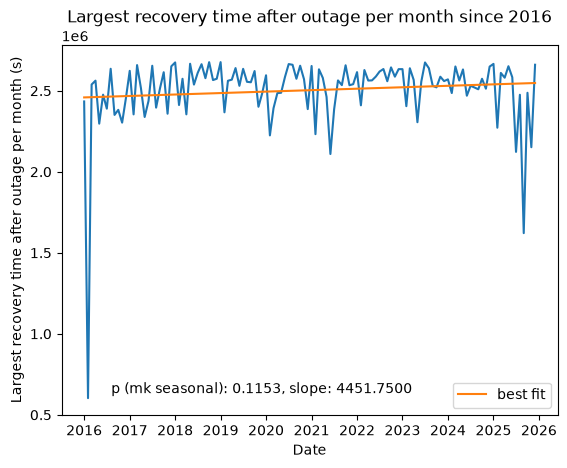

In [90]:
plt.plot(construct_date_axis(len(largest_recovery_times), 2016), largest_recovery_times)
plt.xlabel("Date")
plt.ylabel("Largest recovery time after outage per month (s)")
plt.title("Largest recovery time after outage per month since 2016")

plt.plot(construct_date_axis(len(largest_recovery_times), 2016), PostDataStats.get_regression_line(largest_recovery_times), label="best fit")
regression = PostDataStats.linear_regress(largest_recovery_times)
plt.text(0.10, 0.05,
         f"p (mk seasonal): {largest_recovery_times_mk.p:.4f}, slope: {largest_recovery_times_mk.slope:.4f}",
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         fontsize=10)
plt.legend(loc="lower right")
print(regression.pvalue)

In [10]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = Statistics()
skewness = dataloader.run_on_data(stats.skewness)
print(skewness)   

found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

In [57]:
skewness_mk = mk.seasonal_test(skewness, period=12)
print(skewness_mk)

Seasonal_Mann_Kendall_Test(trend='decreasing', h=np.True_, p=np.float64(0.0), z=np.float64(-9.114420808074788), Tau=np.float64(-0.6555555555555556), s=np.float64(-354.0), var_s=1500.0, slope=np.float64(-0.026637339601733864), intercept=np.float64(0.16398868666142236))


Text(0.5, 1.0, 'Monthly frequency skewness since 2016')

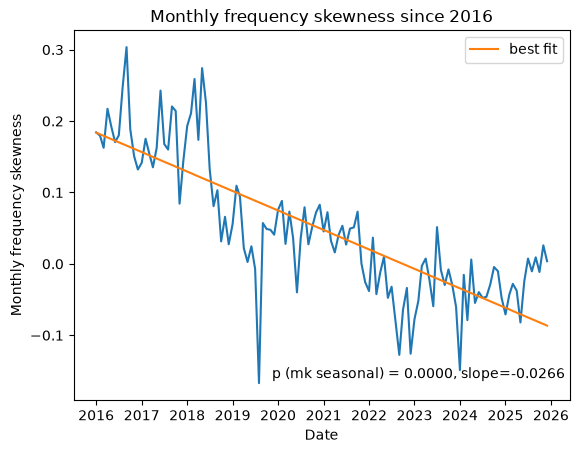

In [50]:
plt.plot(construct_date_axis(len(skewness), 2016), skewness)
plt.plot(construct_date_axis(len(skewness), 2016), PostDataStats.get_regression_line(skewness), label="best fit")
regression = PostDataStats.linear_regress(skewness)
plt.text(0.4, 0.05,
         f"p (mk seasonal) = {skewness_mk.p:.4f}, slope={skewness_mk.slope:.4f}",
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         fontsize=10)
plt.legend(loc="upper right")
plt.xlabel("Date")
plt.ylabel("Monthly frequency skewness")
plt.title("Monthly frequency skewness since 2016")

In [ ]:
plt.plot(construct_date_axis(len()))

In [9]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = Statistics()
result = dataloader.run_on_data(stats.kurtosis)
print(result)   

found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

In [19]:
location = 0
highest = -1000
for x in range(len(result)):
    if result[x] > highest:
        highest = result[x]
        location = x
print(highest)
print (location // 12 + 2016)
print(location % 12 + 1)

2.3836592414420554
2019
8


In [52]:
#we want to exlude the august 2019 blackout from our line of best fit, etc
august_excluded = result[:location] + result[location+1:]
seasonal_mk_kurtosis = mk.seasonal_test(result, period=12)
regression = PostDataStats.linear_regress(august_excluded)
print(regression)

LinregressResult(slope=np.float64(-0.006804379821052178), intercept=np.float64(-0.056905487497586504), rvalue=np.float64(-0.8879978587094337), pvalue=np.float64(2.7756299328248155e-41), stderr=np.float64(0.0003257598903404054), intercept_stderr=np.float64(0.022240121811414566))


In [53]:
print(seasonal_mk_kurtosis)

Seasonal_Mann_Kendall_Test(trend='decreasing', h=np.True_, p=np.float64(0.0), z=np.float64(-10.302135700911728), Tau=np.float64(-0.7407407407407407), s=np.float64(-400.0), var_s=1500.0, slope=np.float64(-0.07719203039658062), intercept=np.float64(-0.051809826506903744))


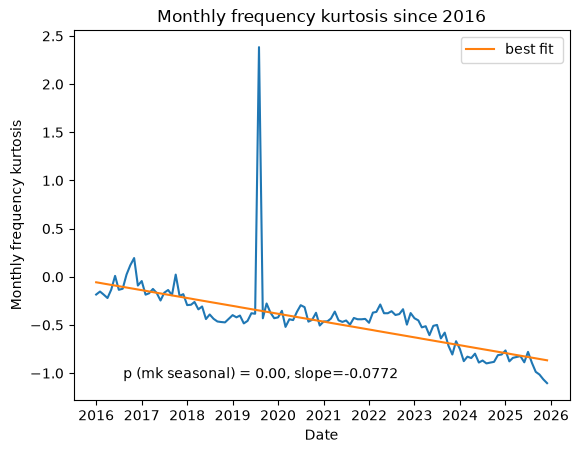

In [54]:
plt.plot(construct_date_axis(len(result), 2016), result)
plt.plot(construct_date_axis(len(result), 2016), regression.slope * (np.array([x for x in range(len(result))])) + regression.intercept, label="best fit ")
plt.text(0.10, 0.05,
         f"p (mk seasonal) = {seasonal_mk_kurtosis.p:.2f}, slope={seasonal_mk_kurtosis.slope:.4f}",
         transform=plt.gca().transAxes,
         verticalalignment='bottom',
         fontsize=10)

plt.xlabel("Date")
plt.ylabel("Monthly frequency kurtosis")
plt.title("Monthly frequency kurtosis since 2016")
plt.legend(loc="upper right")


In [60]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = Statistics()
result = dataloader.run_on_data(stats.spectral_exponent)
print(result)   

found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

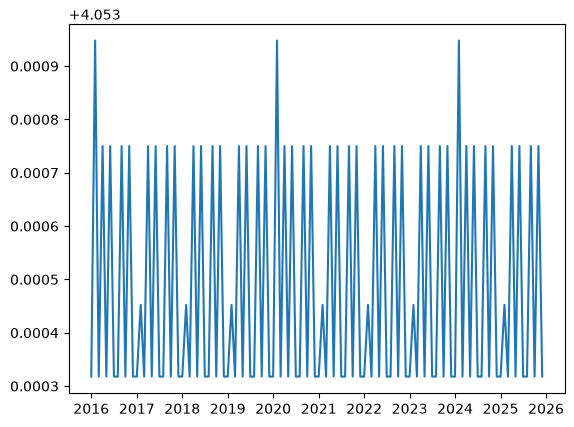

In [61]:
plt.plot(construct_date_axis(len(result), 2016), result)